In [1]:
import json

import numpy as np
import cv2
import matplotlib.pyplot as plt

In [2]:
def rotationMatrixToEulerAngles(R):
    sy = np.sqrt(R[0, 0] * R[0, 0] + R[1, 0] * R[1, 0])
    singular = sy < 1e-6

    if not singular:
        x = np.arctan2(R[2, 1], R[2, 2])  # Roll
        y = np.arctan2(-R[2, 0], sy)      # Pitch
        z = np.arctan2(R[1, 0], R[0, 0])  # Yaw
    else:
        x = np.arctan2(-R[1, 2], R[1, 1]) # Roll
        y = np.arctan2(-R[2, 0], sy)      # Pitch
        z = 0                             # Yaw

    return np.array([x, y, z])

In [4]:
DEFAULT_ARUCO_DICT = cv2.aruco.DICT_4X4_50
MARKER_SIZE = 0.275

In [5]:
dictionary = cv2.aruco.getPredefinedDictionary(DEFAULT_ARUCO_DICT)
parameters = cv2.aruco.DetectorParameters()
detector = cv2.aruco.ArucoDetector(dictionary, parameters)

In [6]:
with open("cam_params.json", "rt") as f:
    params = json.load(f)

cam2 = params["Cam3"]["LENS_PARAMS"]

K = np.array([
    [cam2["FX"], 0, cam2["CX"]],
    [0, cam2["FY"], cam2["CY"]],
    [0, 0, 1],
])
D = np.array([cam2["K0"], cam2["K1"], cam2["K2"], cam2["K3"]])[:, None]

In [7]:
K, D

(array([[201.53031054,   0.        , 332.66330603],
        [  0.        , 201.75347909, 247.36273604],
        [  0.        ,   0.        ,   1.        ]]),
 array([[ 0.35114553],
        [-0.0859251 ],
        [-0.00565496],
        [ 0.0064671 ]]))

In [8]:
# "2024-08-19-11-00-28/video01.avi" - frame 2
# "2024-08-19-10-56-19/video01.avi" - frame 3

In [90]:
frames = []

cap = cv2.VideoCapture("2024-08-19-11-49-25/video01.avi")
while True:
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY))

cap.release()
len(frames)

1220

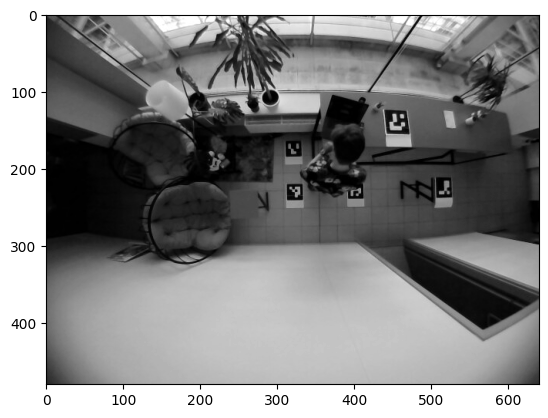

In [91]:
plt.imshow(frames[0], cmap="gray")

In [88]:
# baseline - 46, 70, 123
# 1 - 144, 151, 175
# 2 - 295, 302, 306
# 3 - 420, 425, 463
# 4 - 625, 630, 635
# 5 - 780, 790, 811

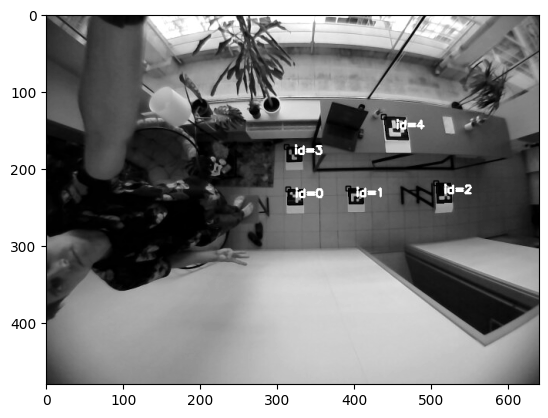

In [96]:
idx = 480
img_gray = frames[idx]

corners, ids, rejected_points = detector.detectMarkers(img_gray)
len(ids)

tmp = img_gray.copy()
cv2.aruco.drawDetectedMarkers(tmp, corners, ids)
cv2.aruco.drawDetectedMarkers(tmp, corners, ids)
plt.imshow(tmp, cmap="gray")

In [97]:
rotation_vectors, translation_vectors, _objPoints = cv2.aruco.estimatePoseSingleMarkers(corners, MARKER_SIZE, K, D)

[[-0.13028737 -0.14212761  2.77206081]]
Marker ID: [0] Distance: 2.78 meters
Marker ID: [0] - Yaw: 0.31, Pitch: 10.33, Roll: 174.09
[[ 0.94826412 -0.154309    2.89136649]]
Marker ID: [1] Distance: 3.05 meters
Marker ID: [1] - Yaw: -0.29, Pitch: -17.10, Roll: 177.13
[[ 1.97024433 -0.16097754  2.58129324]]
Marker ID: [2] Distance: 3.25 meters
Marker ID: [2] - Yaw: -1.84, Pitch: -24.63, Roll: 178.91
[[-0.15540416 -0.92840427  2.94746839]]
Marker ID: [3] Distance: 3.09 meters
Marker ID: [3] - Yaw: -1.88, Pitch: -0.70, Roll: 164.80
[[ 1.07219239 -0.87684995  2.0628763 ]]
Marker ID: [4] Distance: 2.48 meters
Marker ID: [4] - Yaw: -0.78, Pitch: -17.03, Roll: 166.35


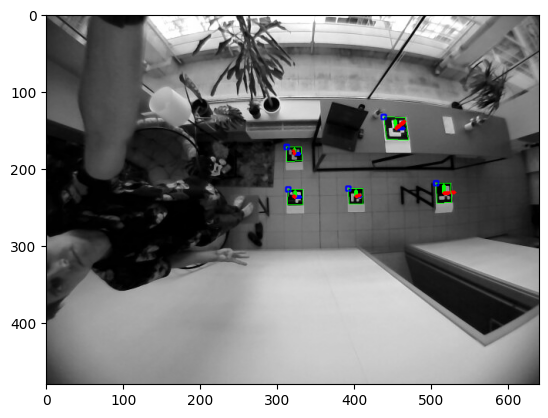

In [98]:
# Convert to grayscale
gray = frames[idx].copy()
frame = cv2.cvtColor(gray.copy(), cv2.COLOR_GRAY2RGB)

dictionary = cv2.aruco.getPredefinedDictionary(DEFAULT_ARUCO_DICT)
parameters = cv2.aruco.DetectorParameters()


# Detect markers
corners, ids, rejected = cv2.aruco.detectMarkers(gray, dictionary, parameters=parameters)

# If markers are detected
if np.all(ids is not None):
    # Estimate pose of each marker
    rvecs, tvecs, _ = cv2.aruco.estimatePoseSingleMarkers(corners, MARKER_SIZE, K, D)
    
    for i in range(len(ids)):
        print(tvecs[i])
        # Draw marker and axis
        cv2.aruco.drawDetectedMarkers(frame, corners)
        cv2.drawFrameAxes(frame, K, D, rvecs[i], tvecs[i], 0.1)
        
        # Distance from the camera to the marker
        distance = np.linalg.norm(tvecs[i])
        print(f"Marker ID: {ids[i]} Distance: {distance:.2f} meters")
        
        # R = rodrigues(rvecs[i].flatten())
        R = cv2.Rodrigues(rvecs[i].flatten())[0]
        euler_angles = rotationMatrixToEulerAngles(R)
        euler_angles_degrees = np.degrees(euler_angles)
        
        print(f"Marker ID: {ids[i]} - Yaw: {euler_angles_degrees[2]:.2f}, Pitch: {euler_angles_degrees[1]:.2f}, Roll: {euler_angles_degrees[0]:.2f}")

plt.imshow(frame)

In [ ]:
# table - 110 cm
# chair - 75 cm

# table marker approx x - 0.9, y - 0.6 m

# window marker 0.75 m by y axis